# 02 · Análisis exploratorio univariado

Describimos cada variable por separado antes de compararla con la nota final. Para las categorías mostramos frecuencias; para las medidas numéricas revisamos sus distribuciones y estadísticos.

## 1. Librerías y carga de datos

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

raiz = Path.cwd()
if not (raiz / 'datos').is_dir():
    raiz = raiz.parent
if not (raiz / 'datos').is_dir():
    raise FileNotFoundError('Abre el proyecto o la carpeta notebooks antes de ejecutar.')
resultados = raiz / 'resultados'
resultados.mkdir(exist_ok=True)
fuentes = {'matematicas': 'student-mat.csv', 'portugues': 'student-por.csv'}
datos = {nombre: pd.read_csv(raiz / 'datos' / archivo, sep=';')
         for nombre, archivo in fuentes.items()}
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid', palette='deep')


## 2. Estadísticos y valores faltantes

In [2]:
numericas = ['age', 'studytime', 'goout', 'Dalc', 'Walc', 'absences', 'failures', 'G1', 'G2', 'G3']
for nombre, df in datos.items():
    print(f'\n{nombre.upper()} · estadísticos descriptivos')
    display(df[numericas].describe().round(2))
    display(df.isna().sum().rename('nulos').to_frame())
    df.describe(include='all').to_csv(resultados / f'estadisticas_{nombre}.csv', encoding='utf-8')
    df.isna().sum().rename('nulos').to_csv(resultados / f'nulos_{nombre}.csv', encoding='utf-8')



MATEMATICAS · estadísticos descriptivos


,age,studytime,goout,Dalc,Walc,absences,failures,G1,G2,G3
count,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00
mean,16.70,2.04,3.11,1.48,2.29,5.71,0.33,10.91,10.71,10.42
std,1.28,0.84,1.11,0.89,1.29,8.00,0.74,3.32,3.76,4.58
min,15.00,1.00,1.00,1.00,1.00,0.00,0.00,3.00,0.00,0.00
25%,16.00,1.00,2.00,1.00,1.00,0.00,0.00,8.00,9.00,8.00
50%,17.00,2.00,3.00,1.00,2.00,4.00,0.00,11.00,11.00,11.00
75%,18.00,2.00,4.00,2.00,3.00,8.00,0.00,13.00,13.00,14.00
max,22.00,4.00,5.00,5.00,5.00,75.00,3.00,19.00,19.00,20.00


,nulos
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0



PORTUGUES · estadísticos descriptivos


,age,studytime,goout,Dalc,Walc,absences,failures,G1,G2,G3
count,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00
mean,16.74,1.93,3.18,1.50,2.28,3.66,0.22,11.40,11.57,11.91
std,1.22,0.83,1.18,0.92,1.28,4.64,0.59,2.75,2.91,3.23
min,15.00,1.00,1.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00
25%,16.00,1.00,2.00,1.00,1.00,0.00,0.00,10.00,10.00,10.00
50%,17.00,2.00,3.00,1.00,2.00,2.00,0.00,11.00,11.00,12.00
75%,18.00,2.00,4.00,2.00,3.00,6.00,0.00,13.00,13.00,14.00
max,22.00,4.00,5.00,5.00,5.00,32.00,3.00,19.00,19.00,19.00


,nulos
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


`G3` es la nota final. Los valores cero están dentro de la escala y se conservan. Una media resume el conjunto, mientras que la mediana ayuda a reconocer el centro cuando hay valores alejados.

## 3. Frecuencias de hábitos

In [3]:
etiquetas = {1: 'Menos de 2 h', 2: '2 a 5 h', 3: '5 a 10 h', 4: 'Más de 10 h'}
for nombre, df in datos.items():
    print(f'\n{nombre.upper()} · tiempo de estudio semanal')
    frecuencia = df['studytime'].value_counts().sort_index()
    display(pd.DataFrame({'Intervalo': [etiquetas[i] for i in frecuencia.index],
                          'Registros': frecuencia.values,
                          'Porcentaje': (frecuencia.values / len(df) * 100).round(1)}))



MATEMATICAS · tiempo de estudio semanal


,Intervalo,Registros,Porcentaje
0,Menos de 2 h,105,26.6
1,2 a 5 h,198,50.1
2,5 a 10 h,65,16.5
3,Más de 10 h,27,6.8



PORTUGUES · tiempo de estudio semanal


,Intervalo,Registros,Porcentaje
0,Menos de 2 h,212,32.7
1,2 a 5 h,305,47.0
2,5 a 10 h,97,14.9
3,Más de 10 h,35,5.4


## 4. Distribución de notas y ausencias

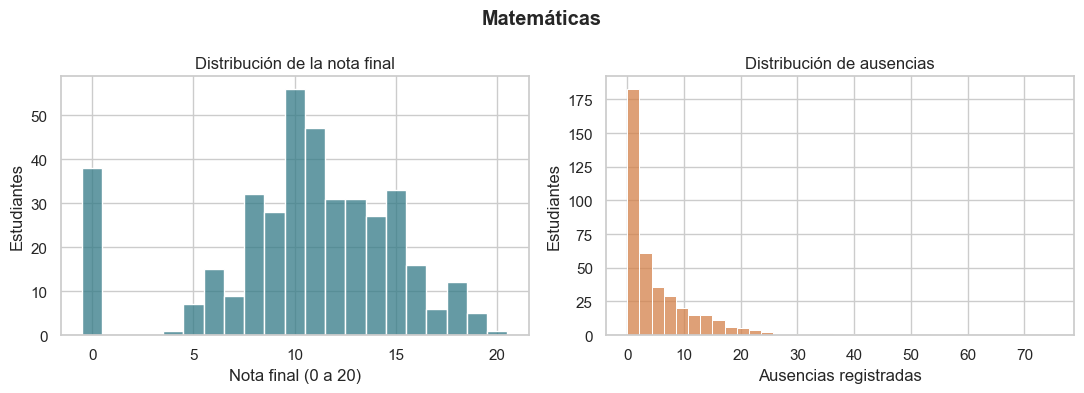

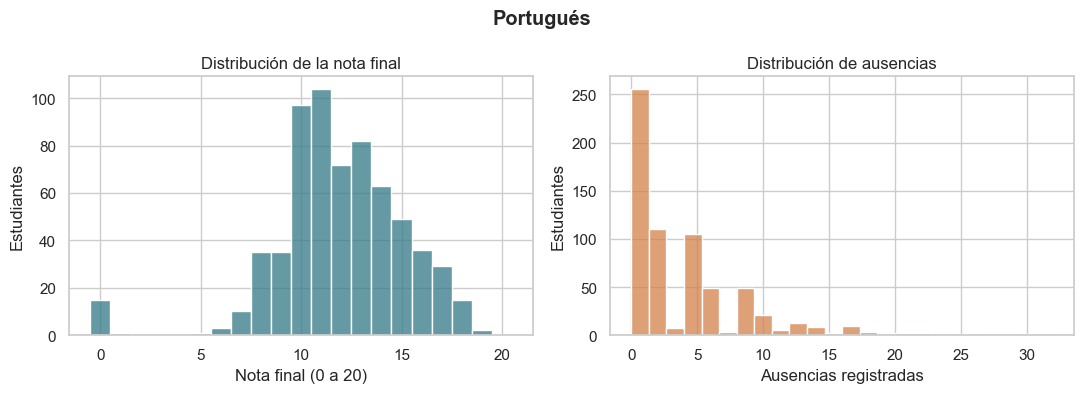

In [4]:
for nombre, df in datos.items():
    fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
    sns.histplot(data=df, x='G3', bins=21, binrange=(-0.5, 20.5), color='#327986', ax=ejes[0])
    ejes[0].set(xlabel='Nota final (0 a 20)', ylabel='Estudiantes', title='Distribución de la nota final')
    sns.histplot(data=df, x='absences', color='#d48149', ax=ejes[1])
    ejes[1].set(xlabel='Ausencias registradas', ylabel='Estudiantes', title='Distribución de ausencias')
    fig.suptitle({'matematicas': 'Matemáticas', 'portugues': 'Portugués'}[nombre], fontweight='bold')
    fig.tight_layout()
    fig.savefig(resultados / f'univariado_{nombre}.png', dpi=150, bbox_inches='tight')
    plt.show()


## 5. Lectura inicial

Las distribuciones muestran que las notas y las ausencias varían entre estudiantes. Algunos valores de ausencias son más altos que la mayoría; eso no basta para considerarlos incorrectos. En el cuaderno de preparación revisamos cómo identificarlos sin borrarlos automáticamente.